## IMPORT LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_theme(style='whitegrid')

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


## LOAD CLEANED DATASET

In [2]:
# Load cleaned dataset
df = pd.read_csv(
    '../data/processed/netflix_cleaned.csv'
)

# Display dataset information
print("NETFLIX CLEANED DATASET")
print("=" * 45)

print("Total Records :", df.shape[0])
print("Total Columns :", df.shape[1])

display(df.head())


NETFLIX CLEANED DATASET
Total Records : 8807
Total Columns : 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
# ==========================================
# DATA TYPE VALIDATION
# ==========================================

# Clean whitespace before date conversion
df['date_added'] = df['date_added'].str.strip()

# Convert date_added
df['date_added'] = pd.to_datetime(
    df['date_added'],
    format='mixed',
    errors='coerce'
)

# Display data types
print("DATA TYPES")
print("=" * 45)

print(df.dtypes)

print("\nMissing Values:")
display(df.isnull().sum())


DATA TYPES
show_id                 object
type                    object
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
description             object
dtype: object

Missing Values:


show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

## Exploratory Data Analysis (EDA)

In [4]:

# ==========================================
# MOVIE VS TV SHOW DISTRIBUTION
# ==========================================

content_distribution = (
    df['type']
    .value_counts()
    .reset_index()
)

content_distribution.columns = [
    'Content Type',
    'Total Titles'
]

content_distribution['Percentage'] = (
    content_distribution['Total Titles']
    / len(df) * 100
)

print("MOVIE VS TV SHOW DISTRIBUTION")
print("=" * 45)

display(content_distribution)


MOVIE VS TV SHOW DISTRIBUTION


,Content Type,Total Titles,Percentage
0,Movie,6131,69.615079
1,TV Show,2676,30.384921


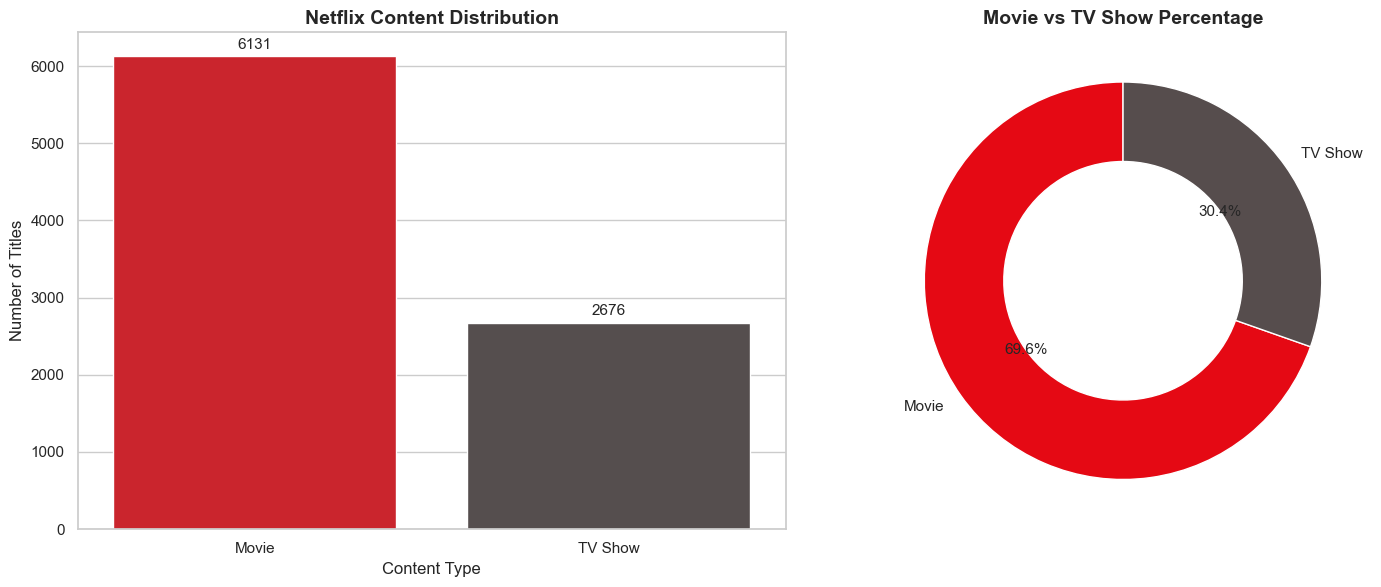

In [5]:

# ==========================================
# CONTENT DISTRIBUTION VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar Chart
sns.barplot(
    data=content_distribution,
    x='Content Type',
    y='Total Titles',
    hue='Content Type',
    palette=['#E50914', '#564D4D'],
    legend=False,
    ax=axes[0]
)

axes[0].set_title(
    'Netflix Content Distribution',
    fontsize=14,
    fontweight='bold'
)

axes[0].set_xlabel('Content Type')
axes[0].set_ylabel('Number of Titles')

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', padding=3)

# Donut Chart
axes[1].pie(
    content_distribution['Total Titles'],
    labels=content_distribution['Content Type'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#E50914', '#564D4D'],
    wedgeprops={
        'width': 0.4,
        'edgecolor': 'white'
    },
    textprops={'fontsize': 11}
)

axes[1].set_title(
    'Movie vs TV Show Percentage',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()



### Key Findings

- Movies dominate Netflix's content catalog,
  accounting for 69.62% of total titles.
- TV Shows represent 30.38% of the catalog.
- The number of Movies is approximately 2.29 times
  higher than TV Shows.
- There is a difference of 3,455 titles between
  Movies and TV Shows.

### Business Insights

Netflix's content catalog is predominantly focused
on movies rather than television series.

Although TV Shows represent a smaller proportion
of the catalog, they provide opportunities for
further analysis of seasonal content and series
distribution.

Understanding this content composition can help
evaluate Netflix's catalog diversification strategy.


In [6]:

# ==========================================
# CONTENT RELEASE YEAR TRENDS
# ==========================================

release_year_trend = (
    df.groupby(['release_year', 'type'])
    .size()
    .reset_index(name='Total Titles')
)

print("CONTENT RELEASE YEAR TRENDS")
print("=" * 50)

display(
    release_year_trend
    .sort_values('release_year', ascending=False)
    .head(15)
)


CONTENT RELEASE YEAR TRENDS


,release_year,type,Total Titles
118,2021,TV Show,315
117,2021,Movie,277
116,2020,TV Show,436
115,2020,Movie,517
114,2019,TV Show,397
113,2019,Movie,633
112,2018,TV Show,380
111,2018,Movie,767
110,2017,TV Show,265
109,2017,Movie,767


In [7]:

# ==========================================
# TOP 10 RELEASE YEARS
# ==========================================

top_release_years = (
    df.groupby('release_year')
    .size()
    .reset_index(name='Total Titles')
    .sort_values('Total Titles', ascending=False)
    .head(10)
)

print("TOP 10 RELEASE YEARS")
print("=" * 45)

display(top_release_years)


TOP 10 RELEASE YEARS


,release_year,Total Titles
70,2018,1147
69,2017,1032
71,2019,1030
72,2020,953
68,2016,902
73,2021,592
67,2015,560
66,2014,352
65,2013,288
64,2012,237


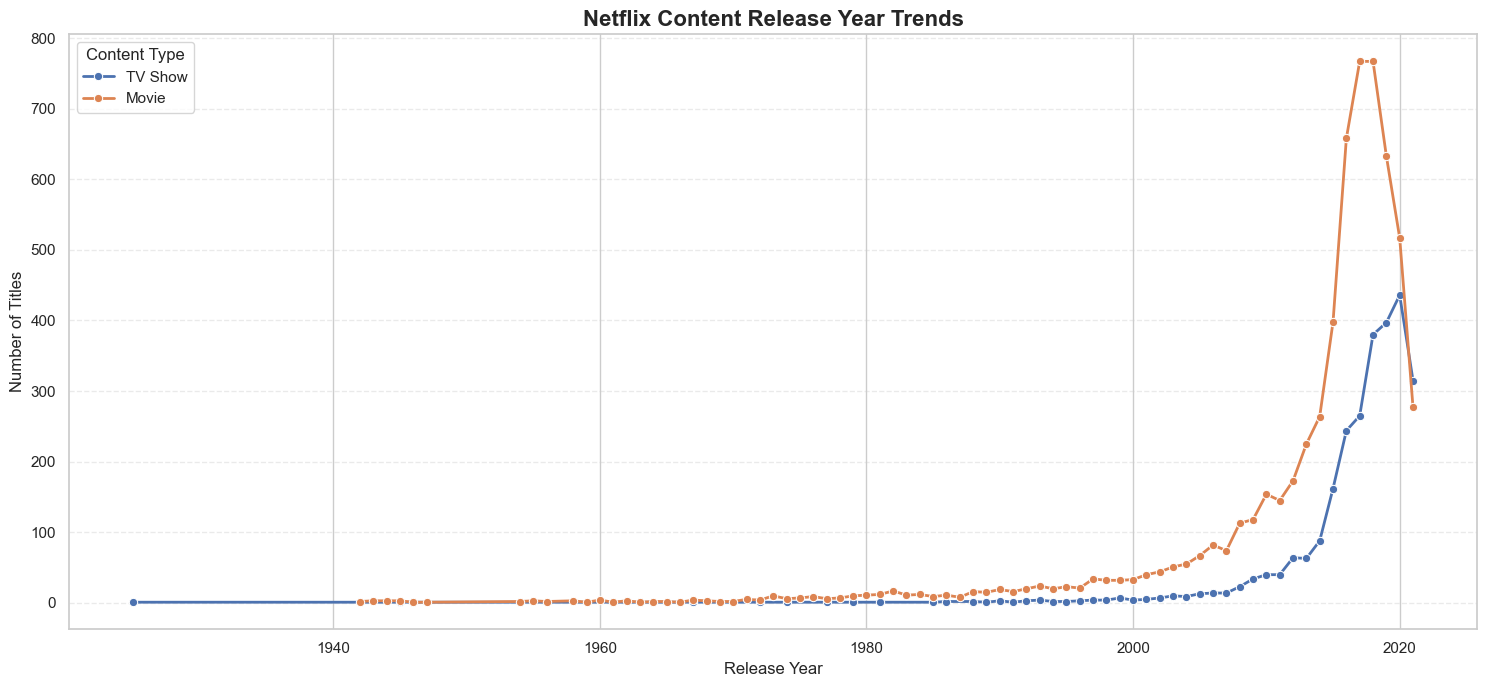

In [8]:

# ==========================================
# RELEASE YEAR TREND VISUALIZATION
# ==========================================

plt.figure(figsize=(15, 7))

sns.lineplot(
    data=release_year_trend,
    x='release_year',
    y='Total Titles',
    hue='type',
    marker='o',
    linewidth=2
)

plt.title(
    'Netflix Content Release Year Trends',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.legend(title='Content Type')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()



### Key Findings

- 2018 recorded the highest number of released titles,
  with 1,147 titles.
- Movies dominated the content distribution across
  most of the top 10 release years.
- Content releases showed a declining pattern
  after reaching their peak in 2018.
- In 2021, TV Shows (315 titles) exceeded Movies
  (277 titles).
- The 2016–2020 period represented the strongest
  release period in the top 10 ranking.

### Business Insights

Netflix's catalog contains a significant concentration
of titles released between 2016 and 2020.

Movies represent the dominant content type across
most of the highest-performing release years.

The shift in 2021, when TV Shows exceeded Movies,
may indicate a change in the composition of Netflix's
content catalog.

Further analysis of content addition dates is needed
to understand Netflix's catalog expansion patterns.


In [9]:

# ==========================================
# PREPARE CONTENT ADDITION DATA
# ==========================================

# Create analysis dataset
content_added = df.dropna(
    subset=['date_added']
).copy()

# Extract date components
content_added['date_added_year'] = (
    content_added['date_added'].dt.year
)

content_added['date_added_month'] = (
    content_added['date_added'].dt.month
)

content_added['date_added_month_name'] = (
    content_added['date_added'].dt.month_name()
)

# Validation
print("CONTENT ADDITION DATA")
print("=" * 45)

print("Original Records :", len(df))
print("Records Analyzed :", len(content_added))
print("Excluded Records :", df['date_added'].isna().sum())

print("\nDate Data Type:")
print(content_added['date_added'].dtype)


CONTENT ADDITION DATA
Original Records : 8807
Records Analyzed : 8797
Excluded Records : 10

Date Data Type:
datetime64[ns]


In [10]:

# ==========================================
# YEARLY CONTENT ADDITION TRENDS
# ==========================================

# Group content by year and type
yearly_content = (
    content_added
    .groupby(['date_added_year', 'type'])
    .size()
    .reset_index(name='Total Titles')
)

print("YEARLY CONTENT ADDITION TRENDS")
print("=" * 50)

display(yearly_content)


YEARLY CONTENT ADDITION TRENDS


,date_added_year,type,Total Titles
0,2008,Movie,1
1,2008,TV Show,1
2,2009,Movie,2
3,2010,Movie,1
4,2011,Movie,13
5,2012,Movie,3
6,2013,Movie,6
7,2013,TV Show,5
8,2014,Movie,19
9,2014,TV Show,5


In [11]:
# ==========================================
# TOTAL CONTENT ADDED BY YEAR
# ==========================================

yearly_total = (
    content_added
    .groupby('date_added_year')
    .size()
    .reset_index(name='Total Titles')
    .sort_values('Total Titles', ascending=False)
)

print("TOP 10 YEARS BY CONTENT ADDITION")
print("=" * 50)

display(yearly_total.head(10))


TOP 10 YEARS BY CONTENT ADDITION


,date_added_year,Total Titles
11,2019,2016
12,2020,1879
10,2018,1649
13,2021,1498
9,2017,1188
8,2016,429
7,2015,82
6,2014,24
3,2011,13
5,2013,11


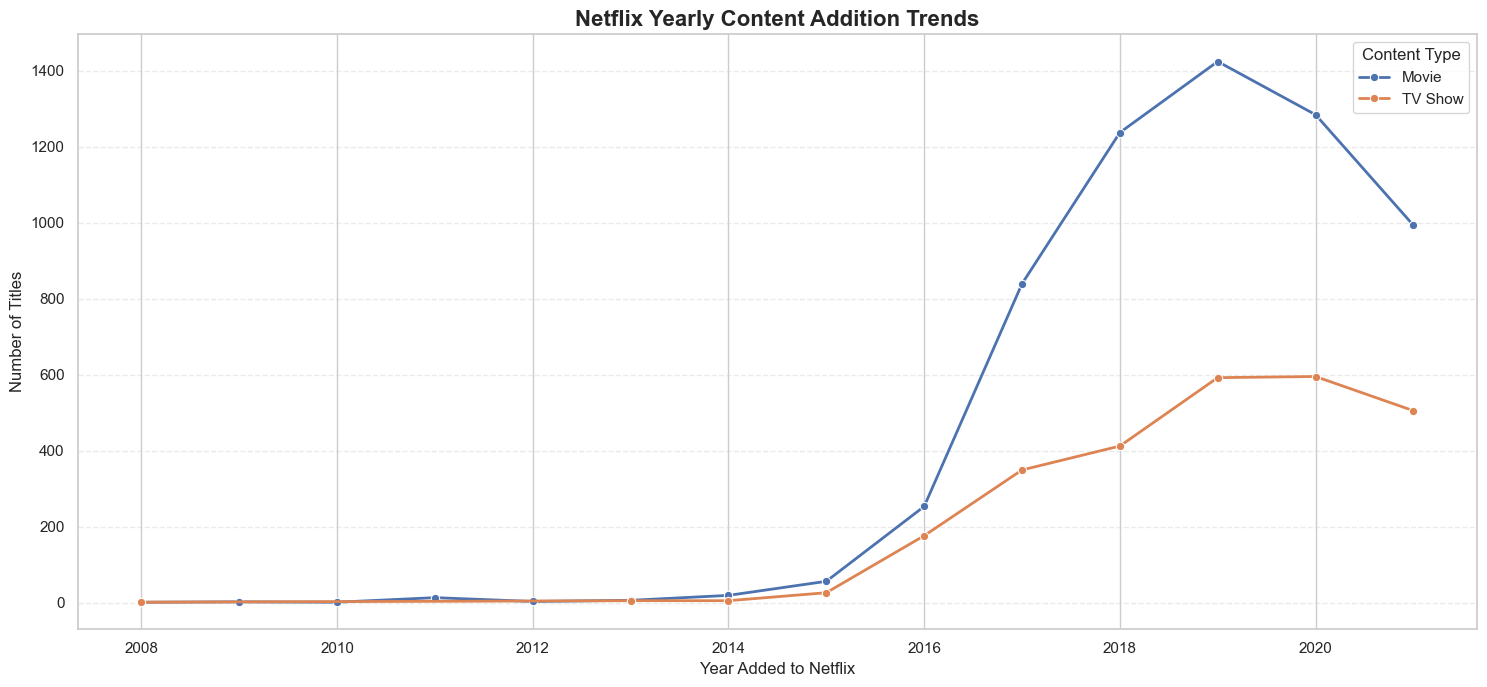

In [12]:
# ==========================================
# YEARLY CONTENT ADDITION VISUALIZATION
# ==========================================

plt.figure(figsize=(15, 7))

sns.lineplot(
    data=yearly_content,
    x='date_added_year',
    y='Total Titles',
    hue='type',
    marker='o',
    linewidth=2
)

plt.title(
    'Netflix Yearly Content Addition Trends',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Year Added to Netflix')
plt.ylabel('Number of Titles')
plt.legend(title='Content Type')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


### Key Findings – Yearly Content Addition Trends

- Netflix recorded its highest content addition in 2019, with 2,016 titles.
- Content additions increased significantly between 2016 and 2019.
- Movie additions consistently outnumbered TV Show additions.
- TV Show additions reached their highest level in 2020, with 595 titles.
- Total content additions declined after reaching their peak in 2019.

### Business Insights

Netflix experienced substantial catalog expansion between 2016 and 2019, 
with Movies contributing the largest share of new additions. Although 
content additions declined after 2019, TV Show additions remained relatively 
high. This suggests that both content acquisition and the development of 
episodic content were important parts of Netflix's catalog strategy.

In [13]:
# MONTHLY CONTENT ADDITION TRENDS

monthly_content = (
    content_added
    .groupby('date_added_month')
    .size()
    .reset_index(name='Total Titles')
)

monthly_content['Month Name'] = (
    pd.to_datetime(monthly_content['date_added_month'], format='%m')
    .dt.month_name()
)

monthly_content = monthly_content[
    ['date_added_month', 'Month Name', 'Total Titles']
].sort_values('date_added_month')

print("MONTHLY CONTENT ADDITION TRENDS")
print("=" * 50)

display(monthly_content)

MONTHLY CONTENT ADDITION TRENDS


,date_added_month,Month Name,Total Titles
0,1,January,738
1,2,February,563
2,3,March,742
3,4,April,764
4,5,May,632
5,6,June,728
6,7,July,827
7,8,August,755
8,9,September,770
9,10,October,760


In [14]:
print("TOP 5 MONTHS BY CONTENT ADDITION")
print("=" * 50)

display(
    monthly_content
    .sort_values('Total Titles', ascending=False)
    .head(5)
)

TOP 5 MONTHS BY CONTENT ADDITION


,date_added_month,Month Name,Total Titles
6,7,July,827
11,12,December,813
8,9,September,770
3,4,April,764
9,10,October,760


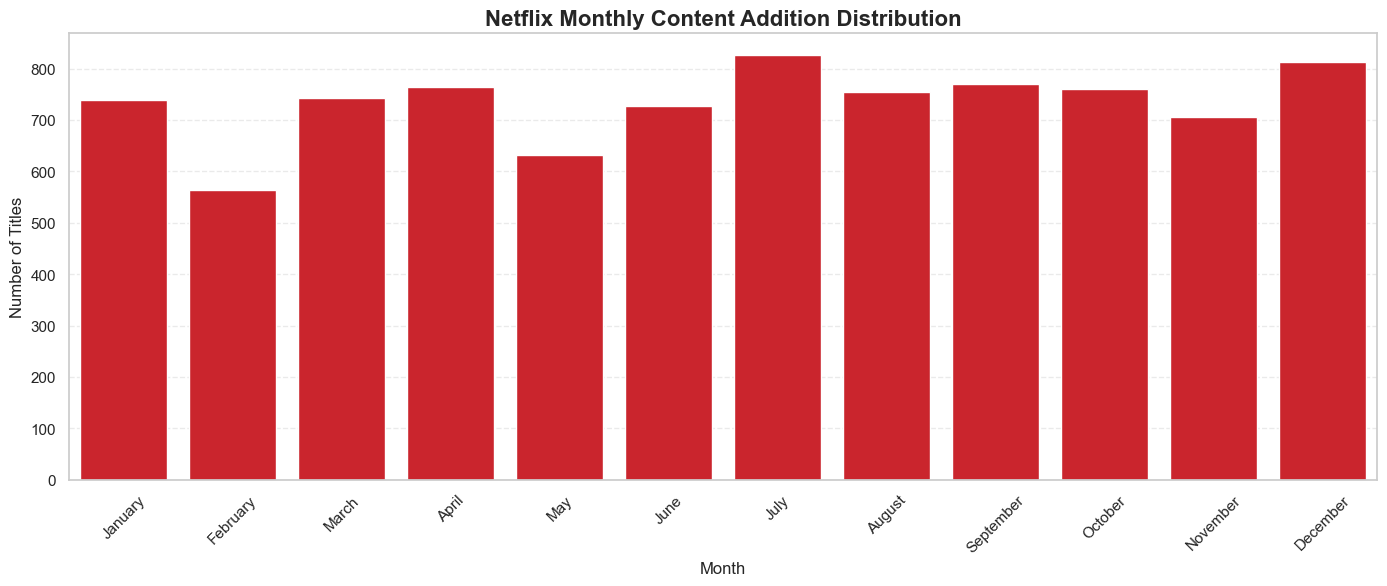

In [15]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=monthly_content,
    x='Month Name',
    y='Total Titles',
    color='#E50914'
)

plt.title(
    'Netflix Monthly Content Addition Distribution',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Month')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Key Findings – Monthly Content Addition Trends

- July recorded the highest content additions with 827 titles.
- December ranked second with 813 titles.
- February had the lowest content additions with 563 titles.
- Content additions were relatively distributed throughout the year.
- No single month overwhelmingly dominated Netflix content additions.

### Business Insights

Netflix's content additions were distributed throughout the year, 
with July and December showing the highest activity. These periods 
may provide useful opportunities for evaluating catalog expansion 
and aligning promotional campaigns with newly added content.

In [16]:
# COUNTRY DATA PREPARATION

country_data = df[['show_id', 'type', 'country']].copy()

# Split multiple countries into separate rows
country_data['country'] = country_data['country'].str.split(',')

country_data = country_data.explode('country')

# Remove leading and trailing spaces
country_data['country'] = country_data['country'].str.strip()

# Remove Unknown values
country_data = country_data[
    country_data['country'].notna() &
    (country_data['country'] != 'Unknown') &
    (country_data['country'] != '')
]

print("COUNTRY DATA VALIDATION")
print("=" * 45)
print("Original Dataset :", len(df))
print("Country Records   :", len(country_data))
print("Unique Countries  :", country_data['country'].nunique())
print("Missing Countries :", country_data['country'].isna().sum())

COUNTRY DATA VALIDATION
Original Dataset : 8807
Country Records   : 10012
Unique Countries  : 122
Missing Countries : 0


In [17]:
# TOP 10 COUNTRIES BY CONTENT

top_countries = (
    country_data
    .groupby('country')
    .size()
    .reset_index(name='Total Titles')
    .sort_values('Total Titles', ascending=False)
    .head(10)
)

print("TOP 10 COUNTRIES BY CONTENT")
print("=" * 50)

display(top_countries)

TOP 10 COUNTRIES BY CONTENT


,country,Total Titles
115,United States,3690
45,India,1046
114,United Kingdom,806
20,Canada,445
36,France,393
53,Japan,318
102,Spain,232
100,South Korea,231
38,Germany,226
67,Mexico,169


In [18]:
# TOP COUNTRIES BY CONTENT TYPE

top_country_names = top_countries['country'].tolist()

country_by_type = (
    country_data[
        country_data['country'].isin(top_country_names)
    ]
    .groupby(['country', 'type'])
    .size()
    .reset_index(name='Total Titles')
)

print("TOP COUNTRIES BY CONTENT TYPE")
print("=" * 50)

display(
    country_by_type.sort_values(
        ['country', 'Total Titles'],
        ascending=[True, False]
    )
)

TOP COUNTRIES BY CONTENT TYPE


,country,type,Total Titles
0,Canada,Movie,319
1,Canada,TV Show,126
2,France,Movie,303
3,France,TV Show,90
4,Germany,Movie,182
5,Germany,TV Show,44
6,India,Movie,962
7,India,TV Show,84
9,Japan,TV Show,199
8,Japan,Movie,119


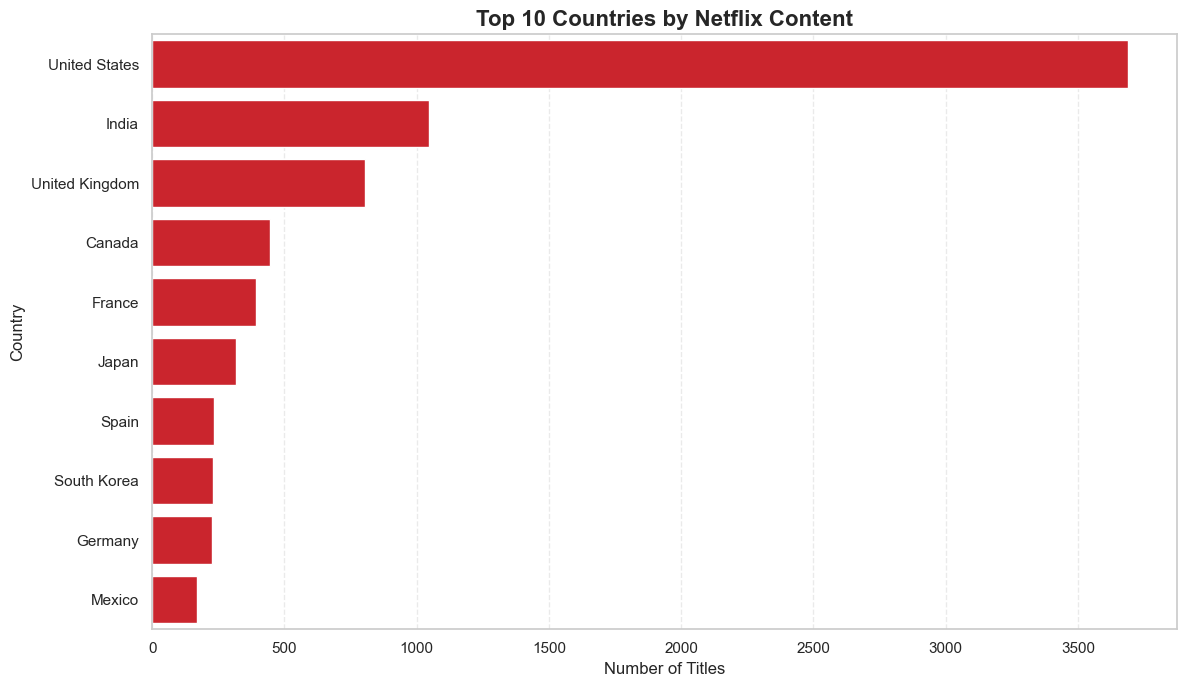

In [19]:
# TOP 10 COUNTRIES VISUALIZATION

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_countries,
    x='Total Titles',
    y='country',
    color='#E50914'
)

plt.title(
    'Top 10 Countries by Netflix Content',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

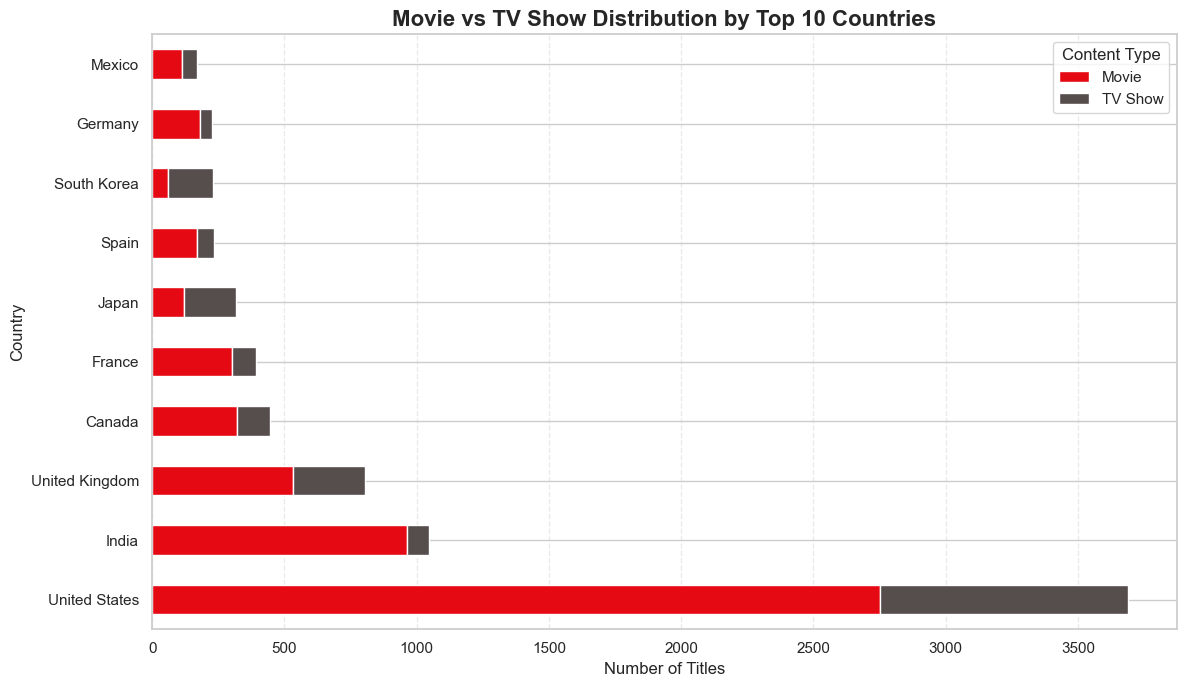

In [20]:
# MOVIE VS TV SHOW BY COUNTRY

country_type_pivot = (
    country_by_type
    .pivot(
        index='country',
        columns='type',
        values='Total Titles'
    )
    .fillna(0)
)

country_type_pivot = country_type_pivot.reindex(
    top_countries['country']
)

country_type_pivot.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 7),
    color=['#E50914', '#564D4D']
)

plt.title(
    'Movie vs TV Show Distribution by Top 10 Countries',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.legend(title='Content Type')
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Key Findings – Top Countries by Content

- The United States dominates Netflix's content catalog with 3,690 titles.
- India ranks second with 1,046 titles, followed by the United Kingdom with 806 titles.
- Movies account for the majority of content from the United States and India.
- Japan and South Korea have more TV Shows than Movies.
- The distribution of Movies and TV Shows varies across countries.

### Business Insights

The United States represents the largest content contributor in the Netflix catalog.
India and the United Kingdom are also significant contributors.

The differences in content type across countries suggest that Netflix's catalog
has varying content characteristics across markets. Japan and South Korea,
for example, have a stronger TV Show presence, while India has a much larger
Movie presence.

These findings can help Netflix evaluate its geographic content portfolio
and understand the diversity of its international catalog.

In [21]:
# GENRE DATA PREPARATION

genre_data = df[['show_id', 'type', 'listed_in']].copy()

# Split multiple genres into separate rows
genre_data['listed_in'] = genre_data['listed_in'].str.split(',')

# Expand genres into separate rows
genre_data = genre_data.explode('listed_in')

# Remove leading and trailing spaces
genre_data['listed_in'] = genre_data['listed_in'].str.strip()

# Remove missing and empty genres
genre_data = genre_data[
    genre_data['listed_in'].notna() &
    (genre_data['listed_in'] != '') &
    (genre_data['listed_in'] != 'Unknown')
]

print("GENRE DATA VALIDATION")
print("=" * 45)
print("Original Dataset :", len(df))
print("Genre Records    :", len(genre_data))
print("Unique Genres    :", genre_data['listed_in'].nunique())
print("Missing Genres   :", genre_data['listed_in'].isna().sum())

GENRE DATA VALIDATION
Original Dataset : 8807
Genre Records    : 19323
Unique Genres    : 42
Missing Genres   : 0


In [22]:
# TOP 10 GENRES BY CONTENT

top_genres = (
    genre_data
    .groupby('listed_in')
    .size()
    .reset_index(name='Total Titles')
    .sort_values('Total Titles', ascending=False)
    .head(10)
)

print("TOP 10 GENRES BY CONTENT")
print("=" * 50)

display(top_genres)

TOP 10 GENRES BY CONTENT


,listed_in,Total Titles
16,International Movies,2752
12,Dramas,2427
7,Comedies,1674
17,International TV Shows,1351
10,Documentaries,869
0,Action & Adventure,859
34,TV Dramas,763
15,Independent Movies,756
4,Children & Family Movies,641
24,Romantic Movies,616


In [23]:
# TOP GENRES BY CONTENT TYPE

top_genre_names = top_genres['listed_in'].tolist()

genre_by_type = (
    genre_data[
        genre_data['listed_in'].isin(top_genre_names)
    ]
    .groupby(['listed_in', 'type'])
    .size()
    .reset_index(name='Total Titles')
)

print("TOP GENRES BY CONTENT TYPE")
print("=" * 50)

display(
    genre_by_type.sort_values(
        ['listed_in', 'Total Titles'],
        ascending=[True, False]
    )
)

TOP GENRES BY CONTENT TYPE


,listed_in,type,Total Titles
0,Action & Adventure,Movie,859
1,Children & Family Movies,Movie,641
2,Comedies,Movie,1674
3,Documentaries,Movie,869
4,Dramas,Movie,2427
5,Independent Movies,Movie,756
6,International Movies,Movie,2752
7,International TV Shows,TV Show,1351
8,Romantic Movies,Movie,616
9,TV Dramas,TV Show,763


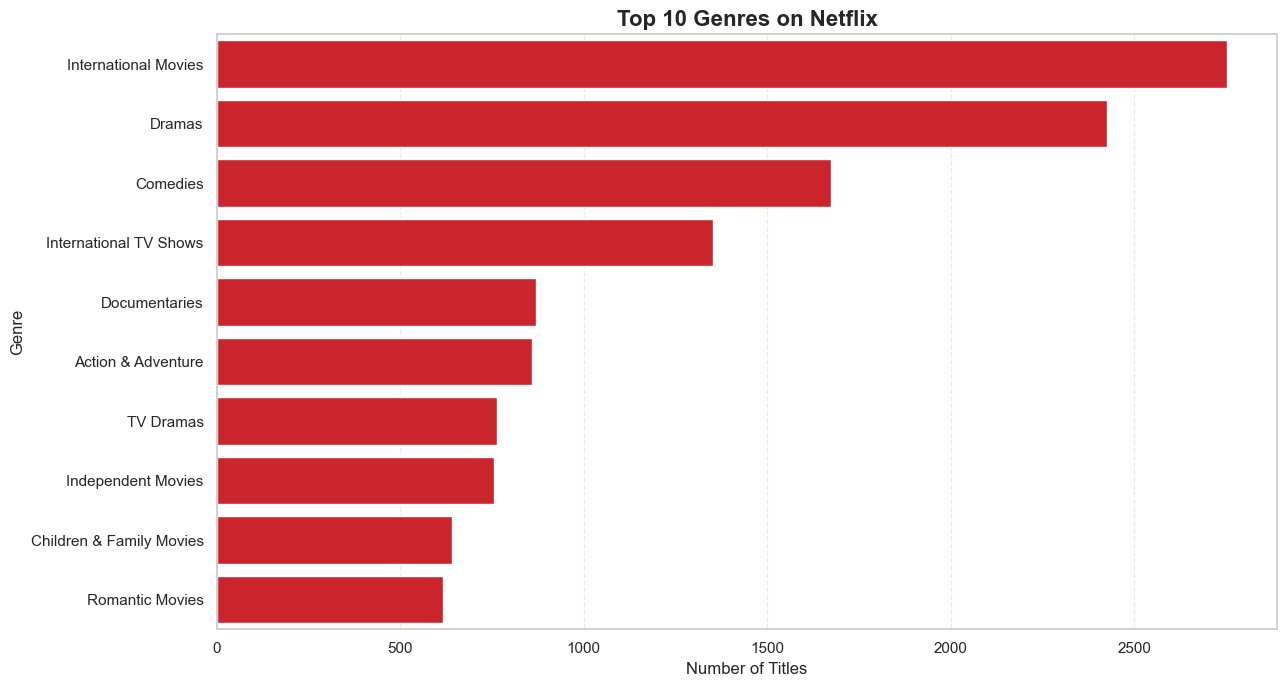

In [24]:
# TOP 10 GENRES VISUALIZATION

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_genres,
    x='Total Titles',
    y='listed_in',
    color='#E50914'
)

plt.title(
    'Top 10 Genres on Netflix',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

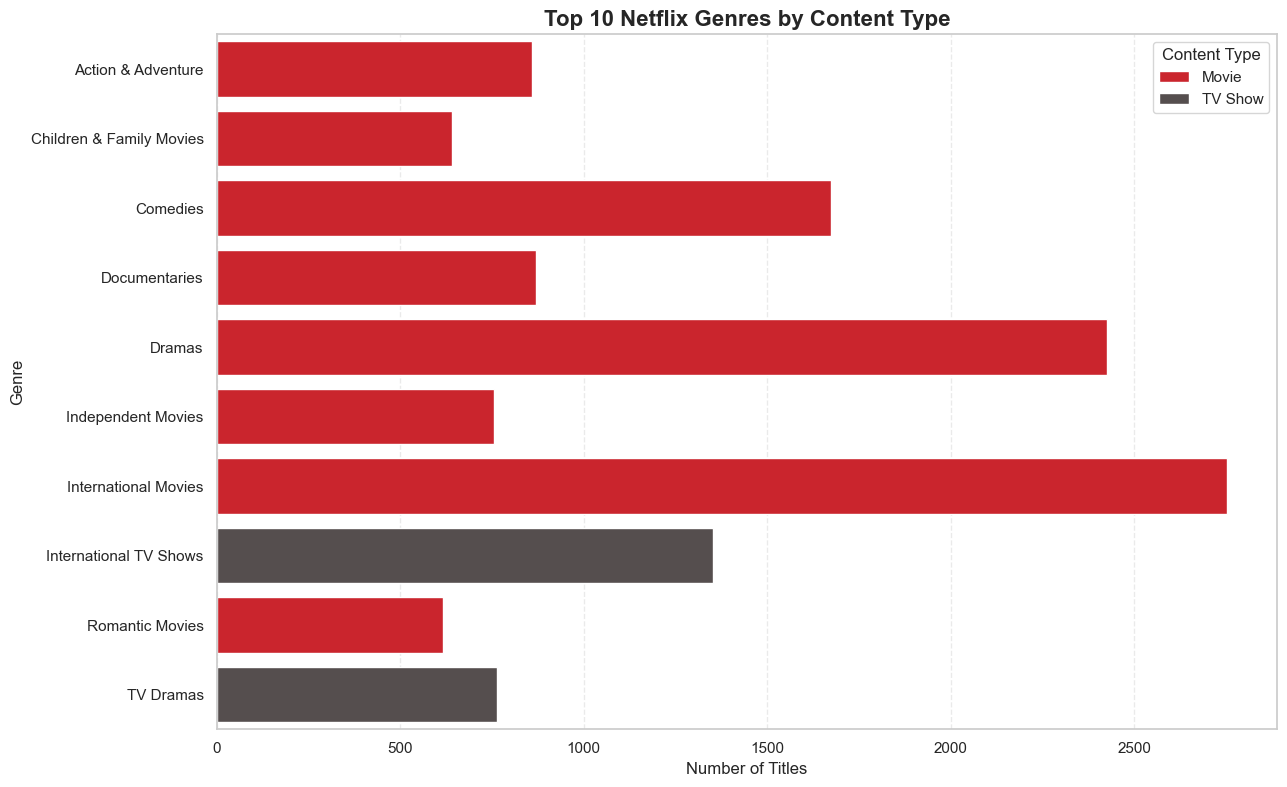

In [25]:
# GENRE DISTRIBUTION BY CONTENT TYPE

plt.figure(figsize=(13, 8))

sns.barplot(
    data=genre_by_type,
    x='Total Titles',
    y='listed_in',
    hue='type',
    palette={
        'Movie': '#E50914',
        'TV Show': '#564D4D'
    }
)

plt.title(
    'Top 10 Netflix Genres by Content Type',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.legend(title='Content Type')
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Key Findings – Genre Distribution

- International Movies is the most common genre with 2,752 titles.
- Dramas ranks second with 2,427 titles.
- Comedies ranks third with 1,674 titles.
- International TV Shows is the most common TV Show genre among the top 10.
- Movie-related genres dominate the top 10 genre categories.
- Netflix's catalog contains 42 unique genres.

### Business Insights

Netflix's content catalog has a strong presence of international content,
dramas, and comedies. This indicates that these categories represent
important components of its content portfolio.

The distribution also highlights differences between Movies and TV Shows.
International Movies and Dramas are prominent in the Movie catalog,
while International TV Shows and TV Dramas are important categories
within the TV Show catalog.

Netflix can use these findings to evaluate genre diversity, identify
content categories with strong catalog representation, and support
future content acquisition and recommendation strategies.

In [26]:
# RATING DATA VALIDATION

rating_data = df[['show_id', 'type', 'rating']].copy()

print("RATING DATA VALIDATION")
print("=" * 45)

print("Total Records    :", len(rating_data))
print("Unique Ratings   :", rating_data['rating'].nunique())
print("Missing Ratings  :", rating_data['rating'].isna().sum())
print("Unknown Ratings  :", (rating_data['rating'] == 'Unknown').sum())

print("\nRATING VALUES")
print("=" * 45)

display(
    rating_data['rating']
    .value_counts()
    .reset_index()
    .rename(columns={
        'index': 'Rating',
        'count': 'Total Titles'
    })
)

RATING DATA VALIDATION
Total Records    : 8807
Unique Ratings   : 15
Missing Ratings  : 0
Unknown Ratings  : 7

RATING VALUES


,rating,Total Titles
0,TV-MA,3207
1,TV-14,2160
2,TV-PG,863
3,R,799
4,PG-13,490
5,TV-Y7,334
6,TV-Y,307
7,PG,287
8,TV-G,220
9,NR,80


In [27]:
# RATING DISTRIBUTION

rating_distribution = (
    rating_data
    .groupby('rating')
    .size()
    .reset_index(name='Total Titles')
    .sort_values('Total Titles', ascending=False)
)

print("RATING DISTRIBUTION")
print("=" * 50)

display(rating_distribution)

RATING DISTRIBUTION


,rating,Total Titles
8,TV-MA,3207
6,TV-14,2160
9,TV-PG,863
5,R,799
4,PG-13,490
11,TV-Y7,334
10,TV-Y,307
3,PG,287
7,TV-G,220
2,NR,80


In [28]:
# RATING DISTRIBUTION BY CONTENT TYPE

rating_by_type = (
    rating_data
    .groupby(['rating', 'type'])
    .size()
    .reset_index(name='Total Titles')
)

print("RATING DISTRIBUTION BY CONTENT TYPE")
print("=" * 50)

display(
    rating_by_type.sort_values(
        ['rating', 'Total Titles'],
        ascending=[True, False]
    )
)

RATING DISTRIBUTION BY CONTENT TYPE


,rating,type,Total Titles
0,G,Movie,41
1,NC-17,Movie,3
2,NR,Movie,75
3,NR,TV Show,5
4,PG,Movie,287
5,PG-13,Movie,490
6,R,Movie,797
7,R,TV Show,2
8,TV-14,Movie,1427
9,TV-14,TV Show,733


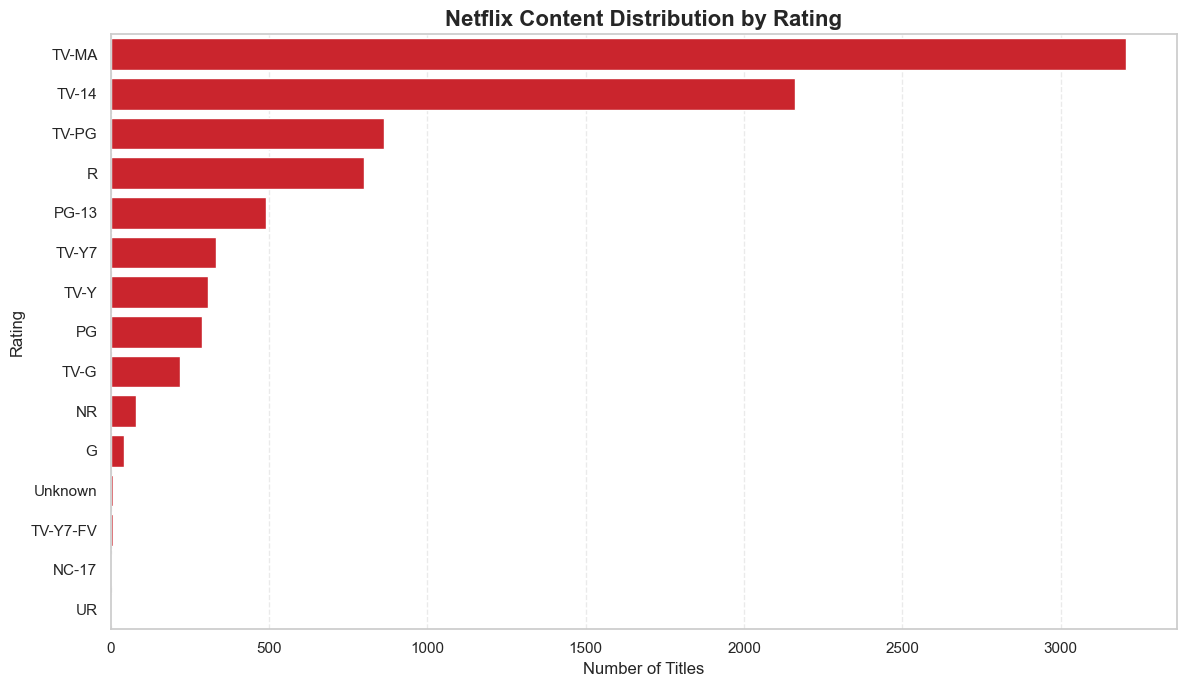

In [29]:
# RATING DISTRIBUTION VISUALIZATION

plt.figure(figsize=(12, 7))

sns.barplot(
    data=rating_distribution,
    x='Total Titles',
    y='rating',
    color='#E50914'
)

plt.title(
    'Netflix Content Distribution by Rating',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Titles')
plt.ylabel('Rating')
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

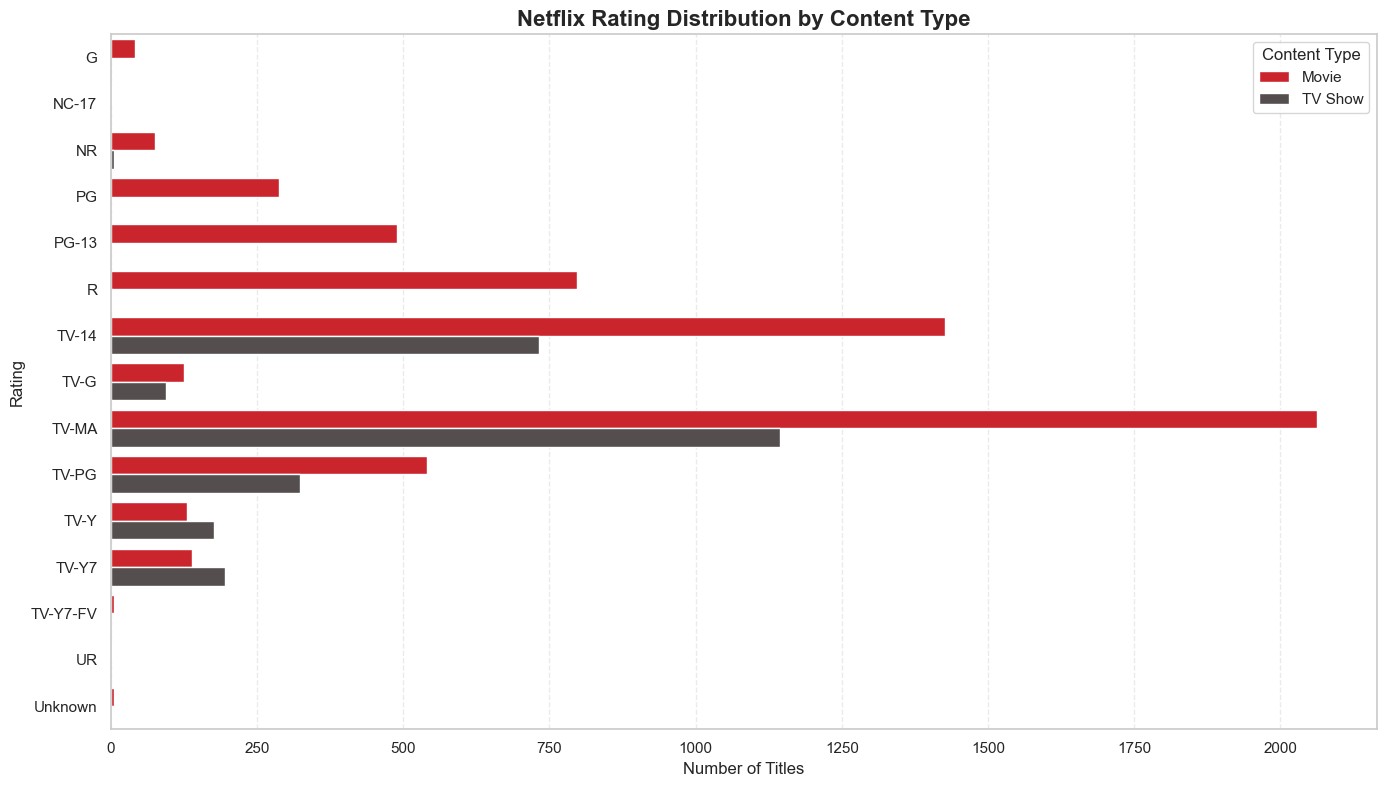

In [30]:
# RATING DISTRIBUTION BY CONTENT TYPE

plt.figure(figsize=(14, 8))

sns.barplot(
    data=rating_by_type,
    x='Total Titles',
    y='rating',
    hue='type',
    palette={
        'Movie': '#E50914',
        'TV Show': '#564D4D'
    }
)

plt.title(
    'Netflix Rating Distribution by Content Type',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Titles')
plt.ylabel('Rating')
plt.legend(title='Content Type')
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Key Findings – Rating Distribution

- TV-MA is the most common rating, with 3,207 titles.
- TV-14 ranks second with 2,160 titles.
- TV-MA and TV-14 together represent approximately 60.9% of the catalog.
- Movie titles dominate the TV-MA and TV-14 categories.
- TV-Y and TV-Y7 have more TV Shows than Movies.
- Seven titles have an Unknown rating.

### Business Insights

Netflix's content catalog is strongly represented by mature-audience
ratings, particularly TV-MA and TV-14. This indicates that adult-oriented
content represents a substantial portion of the available catalog.

However, Netflix also maintains content for younger audiences, as shown
by the presence of TV-Y and TV-Y7 titles.

Understanding rating distribution can help Netflix evaluate its content
portfolio, maintain audience diversity, and support content
recommendations based on viewer age classifications.

In [31]:
# MOVIE DURATION DATA PREPARATION

movie_data = df[df['type'] == 'Movie'].copy()

# Extract duration in minutes
movie_data['duration_minutes'] = (
    movie_data['duration']
    .str.extract(r'(\d+)')
    .astype(float)
)

print("MOVIE DURATION VALIDATION")
print("=" * 45)

print("Total Movies          :", len(movie_data))
print("Valid Duration        :", movie_data['duration_minutes'].notna().sum())
print("Missing Duration      :", movie_data['duration_minutes'].isna().sum())
print("Minimum Duration      :", movie_data['duration_minutes'].min())
print("Maximum Duration      :", movie_data['duration_minutes'].max())

MOVIE DURATION VALIDATION
Total Movies          : 6131
Valid Duration        : 6131
Missing Duration      : 0
Minimum Duration      : 3.0
Maximum Duration      : 312.0


In [32]:
# MOVIE DURATION STATISTICS

duration_stats = movie_data['duration_minutes'].describe()

print("MOVIE DURATION STATISTICS")
print("=" * 45)

display(duration_stats.to_frame(name='Duration (Minutes)'))

MOVIE DURATION STATISTICS


,Duration (Minutes)
count,6131.000000
mean,99.564998
std,28.289504
min,3.000000
25%,87.000000
50%,98.000000
75%,114.000000
max,312.000000


In [33]:
print("MOVIE DURATION SUMMARY")
print("=" * 45)

print("Average Duration :", round(movie_data['duration_minutes'].mean(), 2), "minutes")
print("Median Duration  :", movie_data['duration_minutes'].median(), "minutes")
print("Mode Duration    :", movie_data['duration_minutes'].mode().tolist(), "minutes")

MOVIE DURATION SUMMARY
Average Duration : 99.56 minutes
Median Duration  : 98.0 minutes
Mode Duration    : [90.0] minutes


In [34]:
# TOP 10 SHORTEST MOVIES

shortest_movies = (
    movie_data[['title', 'duration_minutes']]
    .dropna()
    .sort_values('duration_minutes', ascending=True)
    .head(10)
)

print("TOP 10 SHORTEST MOVIES")
print("=" * 50)

display(shortest_movies)

TOP 10 SHORTEST MOVIES


,title,duration_minutes
3777,Silent,3.0
2713,Sol Levante,5.0
1484,Cops and Robbers,8.0
1557,Canvas,9.0
3535,American Factory: A Conversation with the Obamas,10.0
6405,Calico Critters: A Town of Dreams,11.0
2858,Calico Critters: Everyone's Big Dream Flying i...,11.0
695,Besieged Bread,12.0
3775,Cosmos Laundromat: First Cycle,12.0
4707,Zion,12.0


In [35]:
# TOP 10 LONGEST MOVIES

longest_movies = (
    movie_data[['title', 'duration_minutes']]
    .dropna()
    .sort_values('duration_minutes', ascending=False)
    .head(10)
)

print("TOP 10 LONGEST MOVIES")
print("=" * 50)

display(longest_movies)

TOP 10 LONGEST MOVIES


,title,duration_minutes
4253,Black Mirror: Bandersnatch,312.0
717,Headspace: Unwind Your Mind,273.0
2491,The School of Mischief,253.0
2487,No Longer kids,237.0
2484,Lock Your Girls In,233.0
2488,Raya and Sakina,230.0
166,Once Upon a Time in America,229.0
7932,Sangam,228.0
1019,Lagaan,224.0
4573,Jodhaa Akbar,214.0


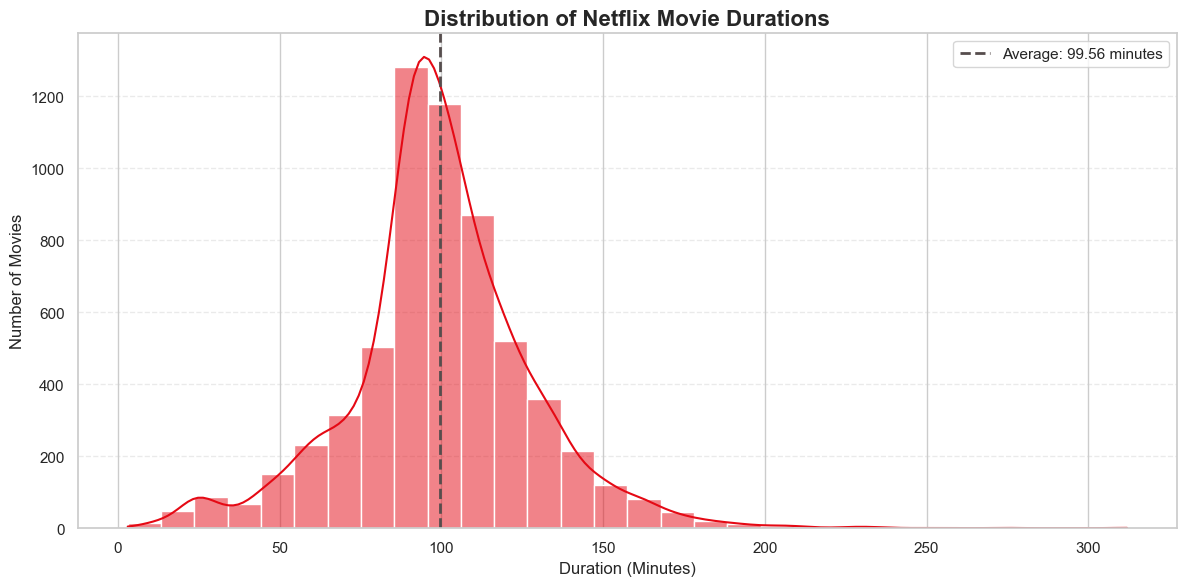

In [36]:
# MOVIE DURATION DISTRIBUTION

plt.figure(figsize=(12, 6))

sns.histplot(
    data=movie_data,
    x='duration_minutes',
    bins=30,
    kde=True,
    color='#E50914'
)

plt.axvline(
    movie_data['duration_minutes'].mean(),
    color='#564D4D',
    linestyle='--',
    linewidth=2,
    label='Average: 99.56 minutes'
)

plt.title(
    'Distribution of Netflix Movie Durations',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

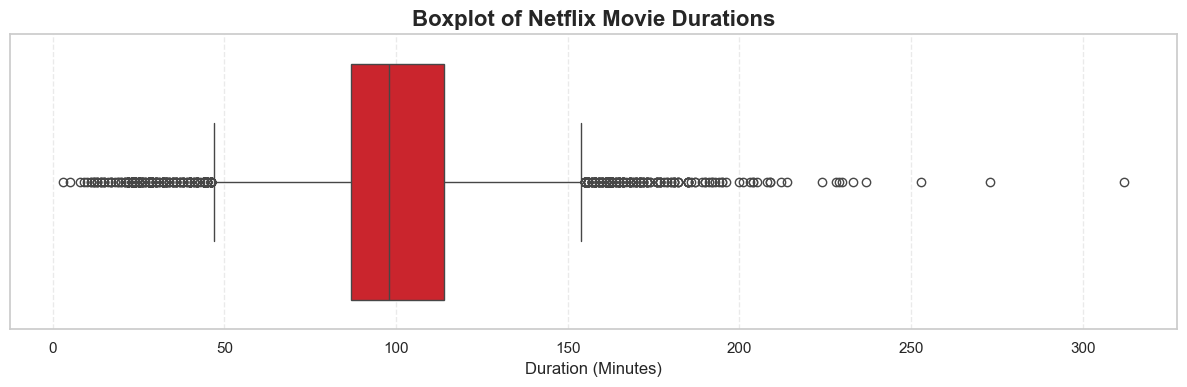

In [37]:
# MOVIE DURATION BOXPLOT

plt.figure(figsize=(12, 4))

sns.boxplot(
    data=movie_data,
    x='duration_minutes',
    color='#E50914'
)

plt.title(
    'Boxplot of Netflix Movie Durations',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Duration (Minutes)')
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Key Findings – Movie Duration Analysis

- Netflix contains 6,131 Movies with valid duration data.
- The average movie duration is 99.56 minutes.
- The median movie duration is 98 minutes.
- The most frequent movie duration is 90 minutes.
- Approximately 50% of movies have durations between 87 and 114 minutes.
- The shortest movie is Silent, with a duration of 3 minutes.
- The longest movie is Black Mirror: Bandersnatch, with a recorded duration of 312 minutes.

### Business Insights

Most Netflix movies have durations centered around 90–100 minutes,
indicating that feature-length content represents a substantial part
of the Movie catalog.

The distribution of movie durations can help Netflix understand
viewing format preferences and evaluate the diversity of its content
catalog, including short-form and long-form movies.

In [38]:
# TV SHOW SEASONS DATA PREPARATION

tv_data = df[df['type'] == 'TV Show'].copy()

# Extract number of seasons
tv_data['season_count'] = (
    tv_data['duration']
    .str.extract(r'(\d+)')
    .astype(float)
)

print("TV SHOW SEASONS VALIDATION")
print("=" * 45)

print("Total TV Shows       :", len(tv_data))
print("Valid Season Count   :", tv_data['season_count'].notna().sum())
print("Missing Season Count :", tv_data['season_count'].isna().sum())
print("Minimum Seasons      :", tv_data['season_count'].min())
print("Maximum Seasons      :", tv_data['season_count'].max())

TV SHOW SEASONS VALIDATION
Total TV Shows       : 2676
Valid Season Count   : 2676
Missing Season Count : 0
Minimum Seasons      : 1.0
Maximum Seasons      : 17.0


In [39]:
# TV SHOW SEASONS STATISTICS

season_stats = tv_data['season_count'].describe()

print("TV SHOW SEASONS STATISTICS")
print("=" * 45)

display(season_stats.to_frame(name='Number of Seasons'))

TV SHOW SEASONS STATISTICS


,Number of Seasons
count,2676.000000
mean,1.764948
std,1.582752
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,17.000000


In [40]:
print("TV SHOW SEASONS SUMMARY")
print("=" * 45)

print("Average Seasons :", round(tv_data['season_count'].mean(), 2))
print("Median Seasons  :", tv_data['season_count'].median())
print("Mode Seasons    :", tv_data['season_count'].mode().tolist())

TV SHOW SEASONS SUMMARY
Average Seasons : 1.76
Median Seasons  : 1.0
Mode Seasons    : [1.0]


In [41]:
# TV SHOW SEASON DISTRIBUTION

season_distribution = (
    tv_data
    .groupby('season_count')
    .size()
    .reset_index(name='Total TV Shows')
    .sort_values('season_count')
)

print("TV SHOW SEASON DISTRIBUTION")
print("=" * 50)

display(season_distribution)

TV SHOW SEASON DISTRIBUTION


,season_count,Total TV Shows
0,1.0,1793
1,2.0,425
2,3.0,199
3,4.0,95
4,5.0,65
5,6.0,33
6,7.0,23
7,8.0,17
8,9.0,9
9,10.0,7


In [42]:
# TOP 10 TV SHOWS WITH MOST SEASONS

longest_tv_shows = (
    tv_data[['title', 'season_count']]
    .dropna()
    .sort_values('season_count', ascending=False)
    .head(10)
)

print("TOP 10 TV SHOWS WITH MOST SEASONS")
print("=" * 50)

display(longest_tv_shows)

TOP 10 TV SHOWS WITH MOST SEASONS


,title,season_count
548,Grey's Anatomy,17.0
4798,NCIS,15.0
2423,Supernatural,15.0
1354,Heartland,13.0
4220,COMEDIANS of the world,13.0
7847,Red vs. Blue,13.0
4964,Trailer Park Boys,12.0
5412,Criminal Minds,12.0
6795,Frasier,11.0
6456,Cheers,11.0


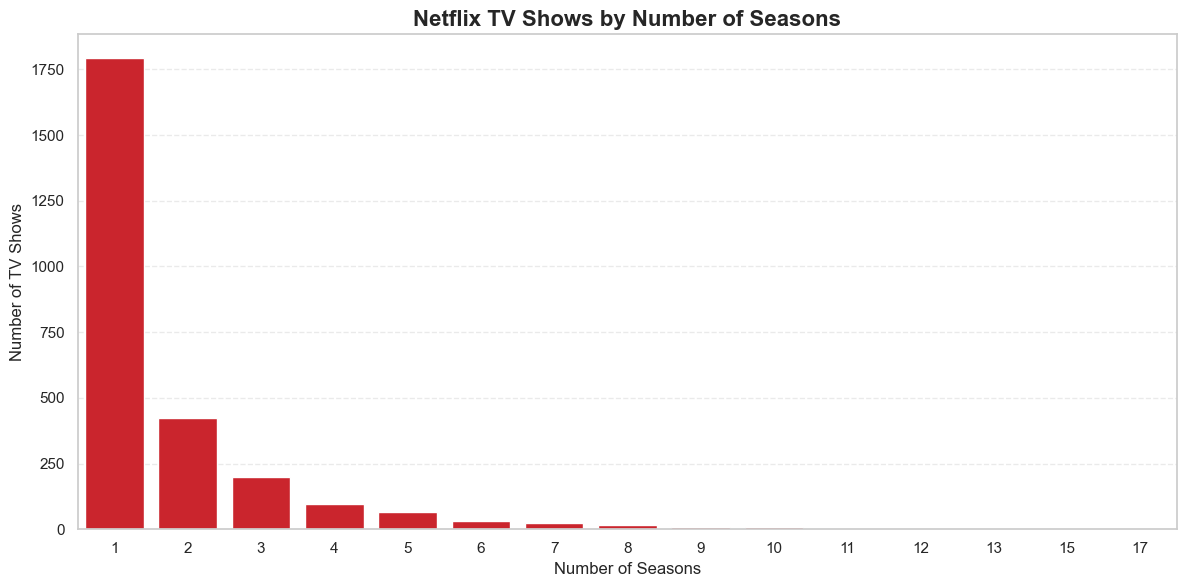

In [43]:
# TV SHOW SEASON DISTRIBUTION VISUALIZATION

plt.figure(figsize=(12, 6))

sns.barplot(
    data=season_distribution,
    x='season_count',
    y='Total TV Shows',
    color='#E50914'
)

plt.title(
    'Netflix TV Shows by Number of Seasons',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Seasons')
plt.ylabel('Number of TV Shows')

plt.xticks(
    ticks=range(len(season_distribution)),
    labels=season_distribution['season_count'].astype(int)
)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

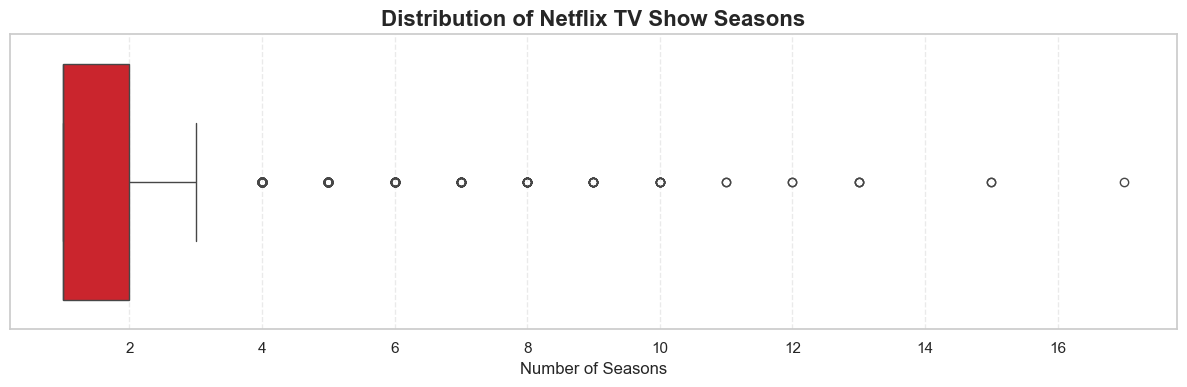

In [44]:
# TV SHOW SEASONS BOXPLOT

plt.figure(figsize=(12, 4))

sns.boxplot(
    data=tv_data,
    x='season_count',
    color='#E50914'
)

plt.title(
    'Distribution of Netflix TV Show Seasons',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Seasons')
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Key Findings – TV Show Seasons Analysis

- Netflix contains 2,676 TV Shows with valid season data.
- The average number of seasons is 1.76.
- The median and mode are both 1 season.
- A total of 1,793 TV Shows (approximately 67%) have only one season.
- Approximately 75% of TV Shows have no more than 2 seasons.
- Grey's Anatomy has the highest number of seasons in the dataset, with 17 seasons.

### Business Insights

Most TV Shows in the Netflix catalog have relatively few seasons,
with approximately 67% consisting of only one season.

This indicates that the catalog contains a substantial number of
limited-season or short-running series. Meanwhile, a smaller portion
of TV Shows has a longer seasonal structure.

Netflix can use these findings to evaluate its TV Show portfolio,
understand the balance between short-running and long-running series,
and support decisions related to content acquisition and retention.

### Business Recommendations

1. Evaluate the balance between Movies and TV Shows to maintain a diverse content catalog.
2. Review content addition trends after 2019 to better understand changes in catalog expansion.
3. Maintain international content diversity by evaluating contributions from different countries.
4. Evaluate genre representation to support a balanced content portfolio.
5. Maintain rating diversity to serve audiences with different age classifications.
6. Evaluate the balance between short-running and long-running TV Shows.
7. Consider movie duration distribution when evaluating content formats.

These recommendations are based on descriptive analysis and should be
validated with additional business, audience engagement, and performance data
before making strategic decisions.

# Final Conclusion

This exploratory data analysis examined 8,807 Netflix titles,
consisting of 6,131 Movies and 2,676 TV Shows.

The analysis identified several important characteristics of
Netflix's content catalog:

- Movies represent approximately 69.62% of all titles.
- Content additions reached their highest level in 2019.
- The United States is the largest content contributor.
- International Movies is the most common genre.
- TV-MA is the most common content rating.
- The average movie duration is approximately 99.56 minutes.
- Most TV Shows have only one season.

Overall, Netflix's catalog is characterized by a strong Movie
presence, substantial international content, and a significant
representation of mature-audience titles.

The findings provide a foundation for developing an interactive
Tableau dashboard to communicate content distribution, geographic
representation, genre characteristics, and catalog expansion trends.

In [45]:
# ==========================================
# 14. EXPORT ANALYTICS DATASETS
# ==========================================

import os

# Membuat folder output
output_path = '../data/processed'

os.makedirs(output_path, exist_ok=True)

# ------------------------------------------
# 1. MAIN DATASET
# ------------------------------------------

main_dataset = df.copy()

# Ekstrak durasi film dalam menit
main_dataset['duration_minutes'] = (
    main_dataset['duration']
    .where(main_dataset['type'] == 'Movie')
    .str.extract(r'(\d+)')[0]
)

main_dataset['duration_minutes'] = pd.to_numeric(
    main_dataset['duration_minutes'],
    errors='coerce'
)

# Ekstrak jumlah season TV Show
main_dataset['season_count'] = (
    main_dataset['duration']
    .where(main_dataset['type'] == 'TV Show')
    .str.extract(r'(\d+)')[0]
)

main_dataset['season_count'] = pd.to_numeric(
    main_dataset['season_count'],
    errors='coerce'
)

# Export main dataset
main_dataset.to_csv(
    f'{output_path}/netflix_main.csv',
    index=False
)

# ------------------------------------------
# 2. COUNTRY DATASET
# ------------------------------------------

country_dataset = df[
    ['show_id', 'type', 'title', 'country']
].copy()

country_dataset['country'] = (
    country_dataset['country']
    .str.split(',')
)

country_dataset = country_dataset.explode('country')

country_dataset['country'] = (
    country_dataset['country'].str.strip()
)

country_dataset = country_dataset[
    country_dataset['country'].notna()
    & (country_dataset['country'] != '')
    & (country_dataset['country'] != 'Unknown')
]

country_dataset.to_csv(
    f'{output_path}/netflix_country.csv',
    index=False
)

# ------------------------------------------
# 3. GENRE DATASET
# ------------------------------------------

genre_dataset = df[
    ['show_id', 'type', 'title', 'listed_in']
].copy()

genre_dataset['listed_in'] = (
    genre_dataset['listed_in']
    .str.split(',')
)

genre_dataset = genre_dataset.explode('listed_in')

genre_dataset['listed_in'] = (
    genre_dataset['listed_in'].str.strip()
)

genre_dataset = genre_dataset[
    genre_dataset['listed_in'].notna()
    & (genre_dataset['listed_in'] != '')
    & (genre_dataset['listed_in'] != 'Unknown')
]

genre_dataset.to_csv(
    f'{output_path}/netflix_genre.csv',
    index=False
)

# ------------------------------------------
# 4. EXPORT VALIDATION
# ------------------------------------------

print("=" * 50)
print("DATASET EXPORT SUCCESSFUL")
print("=" * 50)

print("\nMAIN DATASET")
print("Shape:", main_dataset.shape)

print("\nCOUNTRY DATASET")
print("Shape:", country_dataset.shape)
print("Unique Countries:", country_dataset['country'].nunique())

print("\nGENRE DATASET")
print("Shape:", genre_dataset.shape)
print("Unique Genres:", genre_dataset['listed_in'].nunique())

print(f"\nFiles saved to: {output_path}")

DATASET EXPORT SUCCESSFUL

MAIN DATASET
Shape: (8807, 14)

COUNTRY DATASET
Shape: (10012, 4)
Unique Countries: 122

GENRE DATASET
Shape: (19323, 4)
Unique Genres: 42

Files saved to: ../data/processed
